# 07 — Prior Pre-training for Lorenz-63

This notebook demonstrates a two-stage training strategy for 4DVarNet:

**Stage 1 — Autoencoder pre-training:**
Minimise the reconstruction loss $\|x - \varphi(x)\|^2$ on clean L63
trajectories to obtain a good prior without any observation masking.

**Stage 2 — End-to-end fine-tuning:**
Initialise `FourDVarNet1D` with the pre-trained prior weights and fine-tune
end-to-end on the partially-observed reconstruction task.

We then compare learning curves and final reconstruction quality against
training from scratch (no pre-training).

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax

import vardax
from vardax import (
    Batch1D,
    BilinAEPrior1D,
    FourDVarNet1D,
)
from vardax._src.utils.dynamical_systems import simulate_lorenz63
from vardax._src.utils.patches import trajectory_to_xr_dataset, extract_patches
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import compute_scaler_params, apply_standardization

## 1. Simulate L63 and prepare data

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key, sigma=10.0, rho=28.0, beta=8.0 / 3.0, dt=0.01, n_steps=5000, n_burn_in=1000
)
ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
# Split the trajectory in time *before* cutting windows, so no window
# straddles the boundary: windows drawn at random from one trajectory and
# split afterwards would leak test timesteps into the training set.
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=160, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=40, n_timesteps=20, seed=43)
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
print(f"Train: {batch_train.input.shape}, Test: {batch_test.input.shape}")

Train: (160, 20, 3), Test: (40, 20, 3)


## 2. Stage 1 — Pre-train the prior as an autoencoder

Minimise $\|x - \varphi(x)\|^2$ on clean (unmasked) state trajectories.

In [3]:
# (NNX removed in Epic 0 — vardax is now equinox-native)

B, T, N = batch_train.input.shape
prior = BilinAEPrior1D(state_dim=N, latent_dim=8, n_time=T, key=jax.random.PRNGKey(10))

import equinox as eqx

pre_optimizer = optax.adam(1e-3)
pre_opt_state = pre_optimizer.init(eqx.filter(prior, eqx.is_array))

pretrain_losses = []
n_pretrain_epochs = 20


def pretrain_loss_fn(prior, x):
    x_recon = prior(x)
    return jnp.mean((x - x_recon) ** 2)


for epoch in range(n_pretrain_epochs):
    loss_val, grads = eqx.filter_value_and_grad(pretrain_loss_fn)(
        prior, batch_train.target
    )
    updates, pre_opt_state = pre_optimizer.update(grads, pre_opt_state, prior)
    prior = eqx.apply_updates(prior, updates)
    pretrain_losses.append(float(loss_val))

print(f"Pre-train final loss: {pretrain_losses[-1]:.6f}")

Pre-train final loss: 0.817934


## 3. Stage 2a — Fine-tune with pre-trained prior

In [4]:
model_pretrained = FourDVarNet1D(
    state_dim=N, n_time=T, latent_dim=8, hidden_dim=16, n_solver_steps=10,
    key=jax.random.PRNGKey(1),
)

# Copy pre-trained prior weights into the model's prior sub-module.
# In Equinox, replace the prior subtree in-place with the pre-trained one.
model_pretrained = eqx.tree_at(lambda m: m.prior, model_pretrained, prior)

## 4. Stage 2b — Train from scratch (no pre-training)

In [5]:
model_scratch = FourDVarNet1D(
    state_dim=N, n_time=T, latent_dim=8, hidden_dim=16, n_solver_steps=10,
    key=jax.random.PRNGKey(1),
)

Train both models end-to-end for the same number of epochs.

In [6]:
n_finetune_epochs = 10

model_pretrained, metrics_pretrained, _ = vardax.examples.fit_demo(
    model_pretrained,
    [batch_train],
    n_epochs=n_finetune_epochs,
    lr=1e-3,
    verbose=False,
)

model_scratch, metrics_scratch, _ = vardax.examples.fit_demo(
    model_scratch,
    [batch_train],
    n_epochs=n_finetune_epochs,
    lr=1e-3,
    verbose=False,
)

## 4. Compare learning curves and reconstruction quality

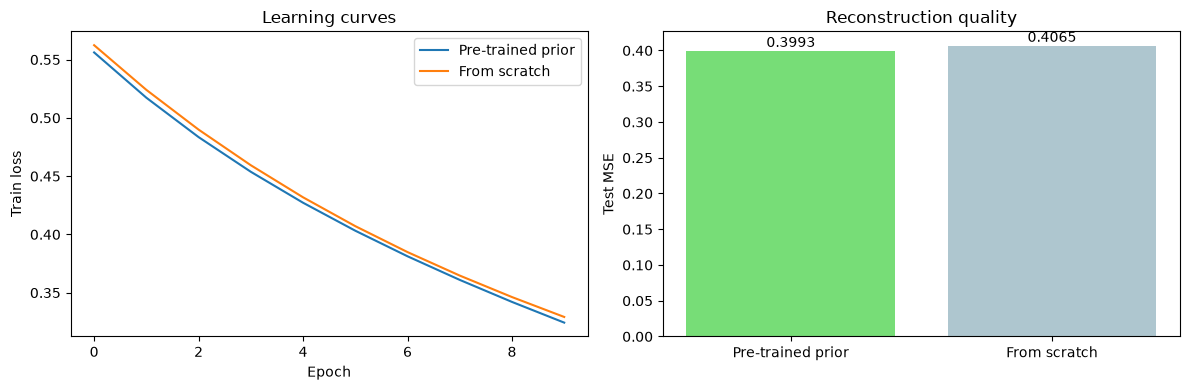

Pre-trained MSE: 0.3993  |  From-scratch MSE: 0.4065


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Learning curves
losses_pretrained = metrics_pretrained
losses_scratch = metrics_scratch
axes[0].plot(losses_pretrained, label="Pre-trained prior")
axes[0].plot(losses_scratch, label="From scratch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Train loss")
axes[0].set_title("Learning curves")
axes[0].legend()

# Final test MSE
out_pretrained = model_pretrained(batch_test)
out_scratch = model_scratch(batch_test)
target = batch_test.target
mse_pretrained = float(jnp.mean((out_pretrained - target) ** 2))
mse_scratch = float(jnp.mean((out_scratch - target) ** 2))

bars = axes[1].bar(
    ["Pre-trained prior", "From scratch"],
    [mse_pretrained, mse_scratch],
    color=["#77dd77", "#aec6cf"],
)
axes[1].set_ylabel("Test MSE")
axes[1].set_title("Reconstruction quality")
for bar, val in zip(bars, [mse_pretrained, mse_scratch]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.001,
        f"{val:.4f}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()
print(f"Pre-trained MSE: {mse_pretrained:.4f}  |  From-scratch MSE: {mse_scratch:.4f}")